# Reimann et al. (2018): GHz rotation of an optically trapped nanoparticle

R. Reimann, M. Doderer, E. Hebestreit, R. Diehl, M. Frimmer, D. Windey, F. Tebbenjohanns and
L. Novotny, *GHz Rotation of an Optically Trapped Nanoparticle in Vacuum*, Phys. Rev. Lett. **121**,
033602 (2018), [doi:10.1103/PhysRevLett.121.033602](https://doi.org/10.1103/PhysRevLett.121.033602)
(open version: arXiv:1803.11160).

A 100 nm silica particle in a nearly circularly polarised 1565 nm tweezer spins up until the optical
torque balances the rotational gas friction, $I\dot\Omega = \tau_\mathrm{opt} - I\Omega/t_\mathrm{damp}$,
so the terminal rate $\Omega_\mathrm{rot} = \tau_\mathrm{opt}t_\mathrm{damp}/I$ is linear in the power
and inverse in the pressure. The paper does not compute $\tau_\mathrm{opt}$; it names three possible
sources (absorption, birefringence, shape asymmetry). levisim computes the optical torque of a dipole
from its polarisability tensor, including the recoil of the radiated angular momentum, and the
rotational gas friction of Martinetz et al. (2018). This notebook

1. checks the scalings $\Omega_\mathrm{rot} \propto P/p_\mathrm{gas}$ with levisim's torque and damping;
2. infers, from the record point, the torque the particle must feel and what it takes to produce it:
   an in-plane shape anisotropy of a lossless particle, or absorption by a sphere;
3. predicts, with that torque, the other quoted rates (655 MHz at 1.1 × 10⁻⁵ mbar, Fig. 2a; Fig. 3a at
   10⁻⁴ mbar);
4. compares the polarisation threshold of Fig. 3b (no rotation within about ±7° of linear
   polarisation) with the two mechanisms;
5. checks the spin-up in the time domain (`RigidBodySimulation`) against τ/(IΓ_rot).

**Comparison stated before running:** the measured maximum $\Omega_\mathrm{rot}/2\pi$ = 1.029(1) GHz at
7.2 × 10⁻⁶ mbar and 226(5) mW focal power (Fig. 2b) and 655 MHz at 1.1 × 10⁻⁵ mbar (Fig. 2a). The
torque is not predicted from first principles (the particle's anisotropy or absorption is unknown):
levisim gives the size of the anisotropy or absorption needed, which is then judged for plausibility,
and the pressure and power scalings, which are compared directly.

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| particle | silica sphere, diameter 100 nm (nominal), fused silica ($n$ at 1565 nm), ρ = 2200 kg/m³ | text ("nominal diameter of 100 nm", "m ≈ 1 fg"); levisim `FUSED_SILICA` |
| tweezer | 1565 nm, focal power 226(5) mW, 0.77 NA aspheric lens | text |
| waist | $w_0 = \lambda/(\pi\,\mathrm{NA})$ = 647 nm (paraxial diffraction limit; not stated) | assumption |
| gas | air at 300 K, full accommodation (levisim's Martinetz friction) | the paper's $t_\mathrm{damp} = \beta m\bar v/(p R^2)$ leaves β free |
| polarisation | circular (`Tweezer.elliptical_polarisation(π/4)`) for the record; ψ swept for Fig. 3b | text, Fig. 3b |

The rotation is about the beam axis $z$ (levisim's and the paper's).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from levisim.core.constants import ε0, π
from levisim.core.logger import logger
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import mbar, mW, nm
from levisim.physics import Gas, Material, Sphere, Spheroid, Trap, Tweezer
from levisim.physics.materials import FUSED_SILICA
from levisim.physics.particle import axis_angle_quaternion, body_axis_to_quaternion
from levisim.physics.rotation import quaternion_multiply
from levisim.simulation import RigidBodySimulation

logger.remove()
set_plt_rcParams_to_xmgrace_style()
t_start = time.time()

λ, R, NA = 1565*nm, 50*nm, 0.77
w0 = λ / (π * NA)
P_record, p_record, f_record = 226*mW, 7.2e-6*mbar, 1.029e9   # Fig. 2b


def circular_tweezer(P=P_record, ψ=π/4):
    return Tweezer(λ=λ, wx0=w0, wy0=w0, Power=P, polarisation=Tweezer.elliptical_polarisation(ψ))


sphere = Sphere(r=R, material=FUSED_SILICA, λ=λ)
I = sphere.inertia_tensor[2, 2]
Γ_record = sphere.rotational_damping_tensor(Gas(P=p_record))[2, 2]
τ_required = I * Γ_record * 2 * π * f_record
tw = circular_tweezer()
print(f'm = {sphere.m:.3e} kg (paper ≈ 1 fg), I = {I:.3e} kg m², εr(1565 nm) = {sphere.εr:.4f}, w0 = {w0 / nm:.0f} nm, E0 = {tw.E0:.3e} V/m')
print(f'rotational gas damping at 7.2e-6 mbar: Γ_rot = {Γ_record:.4e} /s (t_damp = {1 / Γ_record:.1f} s)')
print(f'torque needed for 1.029 GHz: τ = I Γ_rot Ω = {τ_required:.3e} N m')
print(f'torque on the perfect lossless sphere: {tw.torque(np.zeros(3), 0, sphere)[2]:.2e} N m (no spin-up)')

m = 1.152e-18 kg (paper ≈ 1 fg), I = 1.152e-33 kg m², εr(1565 nm) = 2.0847, w0 = 647 nm, E0 = 1.609e+07 V/m
rotational gas damping at 7.2e-6 mbar: Γ_rot = 4.4426e-02 /s (t_damp = 22.5 s)
torque needed for 1.029 GHz: τ = I Γ_rot Ω = 3.310e-25 N m
torque on the perfect lossless sphere: -1.88e-37 N m (no spin-up)


A perfect lossless sphere is not spun up: the angular momentum it takes from the beam (extinction)
it radiates again (scattering). Two levisim mechanisms give a torque.

## Mechanism 1: in-plane shape anisotropy of a lossless particle

A particle with in-plane polarisabilities $\alpha_1 \neq \alpha_2$ scatters circular light anisotropically
and feels $\tau = k^3E_0^2(\alpha_1 - \alpha_2)^2/(24\pi\varepsilon_0)$, independent of its angle. An
equal-volume prolate spheroid lying in the focal plane:

In [2]:
def in_plane_spheroid(aspect, material=FUSED_SILICA, angle=0.0):
    b = R / aspect**(1/3)
    q = quaternion_multiply(axis_angle_quaternion('z', angle), body_axis_to_quaternion((1, 0, 0)))
    return Spheroid(a=aspect * b, b=b, material=material, λ=λ, orientation=q)


def spin_torque(particle, tweezer=None):
    tweezer = circular_tweezer() if tweezer is None else tweezer
    return tweezer.torque(np.zeros(3), 0.0, particle)[2]


aspect_needed = brentq(lambda a: spin_torque(in_plane_spheroid(a)) - τ_required, 1.0001, 2.0)
p_aniso = in_plane_spheroid(aspect_needed)
α_b = np.real(np.diag(p_aniso.static_polarisability_tensor()))
print(f'aspect ratio needed: {aspect_needed:.4f} (Δα/α = {(α_b[2] - α_b[0]) / α_b[0]:.4f}); '
      f'torque {spin_torque(p_aniso):.3e} N m, the same at 0.4 rad: {spin_torque(in_plane_spheroid(aspect_needed, angle=0.4)):.3e}')

aspect ratio needed: 1.1030 (Δα/α = 0.0314); torque 3.310e-25 N m, the same at 0.4 rad: 3.310e-25


## Mechanism 2: absorption by a sphere

The spin torque on an absorbing sphere is the absorbed power over ω. The imaginary part of the
permittivity that gives the record torque:

In [3]:
def absorbing_sphere(ε_imag):
    material = Material('absorbing silica', FUSED_SILICA.ρ, permittivity=sphere.εr + 1j * ε_imag)
    return Sphere(r=R, material=material, λ=λ)


ε_needed = brentq(lambda e: spin_torque(absorbing_sphere(e)) - τ_required, 1e-12, 1e-2)
P_abs = spin_torque(absorbing_sphere(ε_needed)) * tw.ω
n_imag = ε_needed / (2 * np.sqrt(sphere.εr))
print(f"Im ε needed: {ε_needed:.3e} (absorbed power {P_abs:.2e} W; bulk intensity absorption length "
      f"1/(2k Im n) = {1 / (2 * tw.k * n_imag) * 1e2:.0f} cm)")

Im ε needed: 1.022e-06 (absorbed power 3.98e-10 W; bulk intensity absorption length 1/(2k Im n) = 35 cm)


## Pressure and power scaling (Figs. 2b, 3a)

With either mechanism fixed by the record point, levisim's terminal rate $\tau/(I\Gamma_\mathrm{rot}(p))$
at the other quoted conditions:

Ω_rot ∝ p^-1.000000; at 1.1e-5 mbar: 674 MHz (measured 655 MHz, Fig. 2a)
anisotropic: Ω_rot ∝ P^1.000000; at 1e-4 mbar and 150 mW: 49.2 MHz
absorbing: Ω_rot ∝ P^1.000000; at 1e-4 mbar and 150 mW: 49.2 MHz


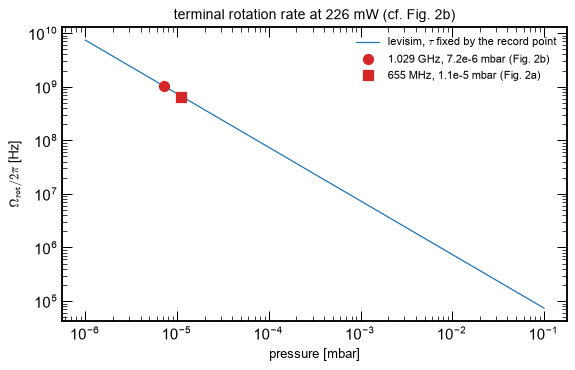

In [4]:
pressures = np.logspace(-6, -1, 51) * mbar
Ω_of_p = np.array([τ_required / (I * sphere.rotational_damping_tensor(Gas(P=p))[2, 2]) for p in pressures]) / (2 * π)
slope = np.polyfit(np.log(pressures), np.log(Ω_of_p), 1)[0]
Ω_655 = τ_required / (I * sphere.rotational_damping_tensor(Gas(P=1.1e-5*mbar))[2, 2]) / (2 * π)
print(f'Ω_rot ∝ p^{slope:.6f}; at 1.1e-5 mbar: {Ω_655 / 1e6:.0f} MHz (measured 655 MHz, Fig. 2a)')

powers = np.linspace(20, 150, 14) * mW
for name, particle in (('anisotropic', p_aniso), ('absorbing', absorbing_sphere(ε_needed))):
    τs = np.array([spin_torque(particle, circular_tweezer(P)) for P in powers])
    rates = τs / (I * sphere.rotational_damping_tensor(Gas(P=1e-4*mbar))[2, 2]) / (2 * π)
    print(f'{name}: Ω_rot ∝ P^{np.polyfit(np.log(powers), np.log(rates), 1)[0]:.6f}; at 1e-4 mbar and 150 mW: {rates[-1] / 1e6:.1f} MHz')

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.loglog(pressures / mbar, Ω_of_p, label=r'levisim, $\tau$ fixed by the record point')
ax.plot([7.2e-6], [1.029e9], 'o', color='C3', label='1.029 GHz, 7.2e-6 mbar (Fig. 2b)')
ax.plot([1.1e-5], [655e6], 's', color='C3', label='655 MHz, 1.1e-5 mbar (Fig. 2a)')
ax.set_xlabel('pressure [mbar]')
ax.set_ylabel(r'$\Omega_\mathrm{rot}/2\pi$ [Hz]')
ax.set_title('terminal rotation rate at 226 mW (cf. Fig. 2b)', fontsize=11)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

The rate is exactly inverse in pressure and linear in power (Fig. 3a's linear fit). The 655 MHz of
Fig. 2a follows from the record point within the accuracy of the pressure readings. Fig. 3a (a
different particle) reaches several tens of MHz at 150 mW and 10⁻⁴ mbar, the order of the prediction.

## Polarisation threshold (Fig. 3b)

In elliptical light a non-spherical particle also feels an aligning torque that pins it to the
polarisation ellipse; it rotates only when the mean (driving) torque exceeds the amplitude of the
aligning one (overdamped Adler criterion). levisim's torque over the particle's angle φ, for the
two mechanisms:

lossless anisotropic particle: drive/pinning at ψ = 7°: 1.11e-05, at ψ = 44°: 1.27e-03; rotates for some ψ ≤ 44°: False
absorbing particle (Im ε = 1.02e-06) with a deterministic threshold at ψ = 7°: aspect ratio 1.0000011 (Δα/α = 3.5e-07); its pinning barrier (the torque amplitude per radian of the cos 2φ potential, ~ amplitude) is 1.9e-05 kT at 300 K
a pinning barrier of 10 kT at ψ = 7° needs aspect 1.807; unpinning it at ψ = 7° takes a drive of 4.1e-20 N m, 1e+05 times the record torque


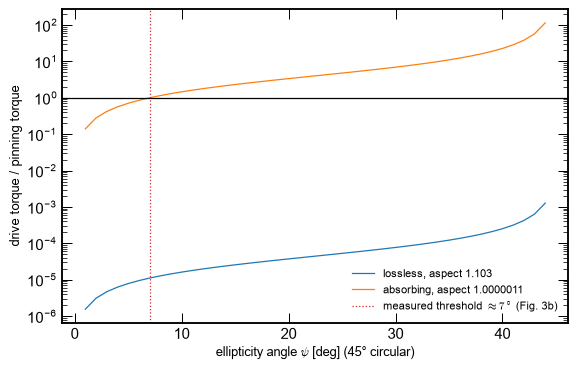

In [5]:
def drive_and_pinning(particle_of_angle, ψ):
    tweezer = circular_tweezer(ψ=ψ)
    angles = np.linspace(0, π, 64, endpoint=False)
    τ = np.array([tweezer.torque(np.zeros(3), 0.0, particle_of_angle(a))[2] for a in angles])
    return τ.mean(), 0.5 * (τ.max() - τ.min())


ψs = np.radians(np.linspace(1, 44, 44))
aniso = np.array([drive_and_pinning(lambda a: in_plane_spheroid(aspect_needed, angle=a), ψ) for ψ in ψs])
rotates = aniso[:, 0] > aniso[:, 1]
print(f'lossless anisotropic particle: drive/pinning at ψ = 7°: {np.interp(7, np.degrees(ψs), aniso[:, 0] / aniso[:, 1]):.2e}, '
      f'at ψ = 44°: {aniso[-1, 0] / aniso[-1, 1]:.2e}; rotates for some ψ ≤ 44°: {bool(np.any(rotates))}')


def absorbing_spheroid(aspect, angle):
    material = Material('absorbing silica', FUSED_SILICA.ρ, permittivity=sphere.εr + 1j * ε_needed)
    return in_plane_spheroid(aspect, material=material, angle=angle)


# the asphericity of an absorbing particle whose pinning stops the rotation below ψ = 7°
def ratio_at_7(aspect):
    drive, pin = drive_and_pinning(lambda a: absorbing_spheroid(aspect, a), np.radians(7))
    return drive / pin - 1


aspect_7 = brentq(ratio_at_7, 1 + 1e-7, 1.01)
b7 = in_plane_spheroid(aspect_7)
α7 = np.real(np.diag(b7.static_polarisability_tensor()))
_, pin_7 = drive_and_pinning(lambda a: absorbing_spheroid(aspect_7, a), np.radians(7))
kT = 1.380649e-23 * 300
print(f'absorbing particle (Im ε = {ε_needed:.2e}) with a deterministic threshold at ψ = 7°: aspect ratio {aspect_7:.7f} '
      f'(Δα/α = {(α7[2] - α7[0]) / α7[0]:.1e}); its pinning barrier (the torque amplitude per radian of the '
      f'cos 2φ potential, ~ amplitude) is {pin_7 / kT:.1e} kT at 300 K')
# the anisotropy whose pinning barrier at ψ = 7° is 10 kT, and the drive it would take to unpin it
aspect_10kT = brentq(lambda a: drive_and_pinning(lambda x: in_plane_spheroid(a, angle=x), np.radians(7))[1] - 10 * kT, 1 + 1e-6, 3.0)
_, pin_10kT = drive_and_pinning(lambda x: in_plane_spheroid(aspect_10kT, angle=x), np.radians(7))
print(f'a pinning barrier of 10 kT at ψ = 7° needs aspect {aspect_10kT:.3f}; unpinning it at ψ = 7° takes a drive '
      f'of {pin_10kT:.1e} N m, {pin_10kT / τ_required:.0e} times the record torque')

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.semilogy(np.degrees(ψs), aniso[:, 0] / aniso[:, 1], label=f'lossless, aspect {aspect_needed:.3f}')
absorbing = np.array([drive_and_pinning(lambda a: absorbing_spheroid(aspect_7, a), ψ) for ψ in ψs])
ax.semilogy(np.degrees(ψs), absorbing[:, 0] / absorbing[:, 1], label=f'absorbing, aspect {aspect_7:.7f}')
ax.axhline(1, color='k', lw=1)
ax.axvline(7, color='C3', ls=':', label=r'measured threshold $\approx 7^\circ$ (Fig. 3b)')
ax.set_xlabel(r'ellipticity angle $\psi$ [deg] (45° circular)')
ax.set_ylabel('drive torque / pinning torque')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

A lossless particle with the 3 % anisotropy needed for the record rate would be pinned for every
ellipticity short of circular (its drive is a scattering effect, 10⁻⁵ of its aligning torque at
ψ = 7°): shape anisotropy alone is incompatible with Fig. 3b. An absorbing particle has a
deterministic threshold at 7° only if its in-plane anisotropy is a few 10⁻⁷, but then its pinning
barrier is far below kT at room temperature and thermal motion would unpin it at any ellipticity.
A barrier that pins at 300 K (≥ 10 kT) needs a strongly anisotropic particle, and unpinning it at 7°
needs a drive about five orders of magnitude above the record torque. The record rate and the polarisation
threshold are therefore not explained together by one particle in levisim's dipole model with
thermal equilibrium at the gas temperature; this stays an open point (the paper does not model the
threshold either; the internal temperature, a non-dipolar shape or the setup's birefringence may
matter). The QWP angle φ of Fig. 3b is identified with ψ, ignoring the window birefringence the
paper invokes for the −6° offset.

## Time domain: spin-up against τ/(IΓ_rot)

The absorbing sphere in circular light at 1 mbar (where the spin-up time 1/Γ_rot is about 0.16 ms),
with gas friction but without its thermal noise, so that the deterministic spin-up is visible:

1 mbar: Γ_rot = 6170.3 /s; terminal Ω/2π = 7408.8 Hz; simulated at t = 10 ms: 7408.8 Hz (analytic 7408.8); max deviation 3.7e-09; backend numba


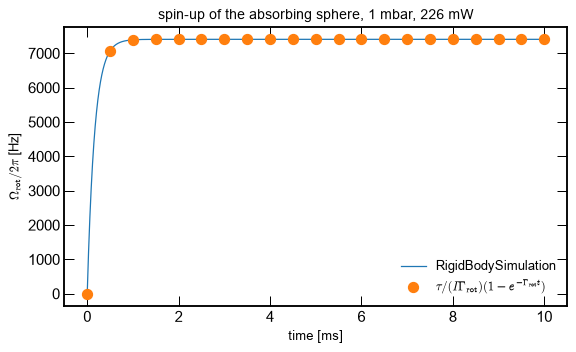

In [6]:
trap = Trap(tweezer=circular_tweezer(), particle=absorbing_sphere(ε_needed), gas=Gas(P=1*mbar),
             finite_size_torque=False)  # a sphere: no finite-size torque
Γ1 = trap.Γrot_j['γ']
τ1 = spin_torque(absorbing_sphere(ε_needed))
Δt = 0.2e-6
sim = RigidBodySimulation(trap=trap, num_samples=50_000, Δt=Δt, gas_noise=False, seed=1)
ω = sim.angular_velocities_lab()[:, 2]
t = sim.time_array
expected = τ1 / (I * Γ1) * (1 - np.exp(-Γ1 * t))
print(f'1 mbar: Γ_rot = {Γ1:.1f} /s; terminal Ω/2π = {τ1 / (I * Γ1) / (2 * π):.1f} Hz; '
      f'simulated at t = {t[-1] * 1e3:.0f} ms: {ω[-1] / (2 * π):.1f} Hz (analytic {expected[-1] / (2 * π):.1f}); '
      f'max deviation {np.max(np.abs(ω - expected)) / expected[-1]:.1e}; backend {sim.backend_used}')

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(t * 1e3, ω / (2 * π), label='RigidBodySimulation')
ax.plot(t[::2500] * 1e3, expected[::2500] / (2 * π), 'o', label=r'$\tau/(I\Gamma_\mathrm{rot})(1 - e^{-\Gamma_\mathrm{rot}t})$')
ax.set_xlabel('time [ms]')
ax.set_ylabel(r'$\Omega_\mathrm{rot}/2\pi$ [Hz]')
ax.set_title('spin-up of the absorbing sphere, 1 mbar, 226 mW', fontsize=11)
ax.legend(frameon=False)
fig.tight_layout()

## Summary

| Quantity | Paper | levisim | Verdict |
|---|---|---|---|
| pressure scaling | $\Omega_\mathrm{rot} \propto 1/p$ (dashed theory, Fig. 2b) | exponent −1.000000 | agree |
| power scaling | linear (Fig. 3a) | exponent 1.000000 | agree |
| 655 MHz at 1.1 × 10⁻⁵ mbar from the 1.029 GHz record | 655 MHz (Fig. 2a) | see the printout (≈ 674 MHz) | agree within the gauge accuracy the paper discusses |
| torque needed for the record | not computed | 3.3 × 10⁻²⁵ N m (Martinetz friction, full accommodation) | — |
| mechanism | absorption, birefringence or shape (open) | shape alone needs 3 % anisotropy (aspect 1.10) and would pin the particle at every ψ < 45°; absorption needs Im ε ≈ 1.0 × 10⁻⁶ | shape alone ruled out by Fig. 3b |
| polarisation threshold ≈ 7° (Fig. 3b) | measured | not explained together with the record rate (pinning that survives 300 K needs a drive ~10⁵ × the record torque) | open |
| time domain | — | spin-up follows τ/(IΓ)(1 − e^{−Γt}) | consistency check |

Not reproduced: the measured rates below 10⁻³ mbar, which the paper itself attributes to the ion
gauge reading low; the absolute torque (it depends on the unknown absorption or anisotropy). The
paper's own damping formula has a free accommodation factor β; levisim's full-accommodation
friction fixes it, so the inferred torque carries that uncertainty.

In [7]:
print(f'computation time {time.time() - t_start:.1f} s')

computation time 2.5 s
